# OE1 · Actividad 2 — Limpieza y normalización de VoxForge Spanish

**Objetivo:** convertir los WAV originales (48 kHz, mono o estéreo) a **WAV PCM_16, mono, 16 kHz**, sin modificar los originales. El procesamiento es **por lotes reanudables** y utiliza `data/metadata/inventario_voxforge.csv` generado en el EDA.

**Ejecución:** correr las celdas 1–5 una vez; repetir la celda 6 para procesar el siguiente lote; usar las celdas 7–9 para auditar resultados. El código no borra audios ni referencias. No aplica filtros de duración ni reducción de ruido, para no alterar la comparación. Las referencias de lectura se tratarán en la siguiente actividad.

In [1]:
# 1. Dependencias: ejecutar en el kernel seleccionado si faltan paquetes
# %pip install pandas numpy soundfile scipy tqdm matplotlib
from pathlib import Path
import os, re, json, time, uuid
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
from math import gcd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
print("Dependencias cargadas.")

d:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dependencias cargadas.


In [8]:
# 2. Rutas y configuración
ROOT = Path.cwd().resolve()
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "data" / "metadata" / "inventario_voxforge.csv").is_file():
    raise FileNotFoundError(f"No existe el inventario bajo {ROOT}. Abre el proyecto desde su raíz o notebooks/.")
RAW = ROOT / "data" / "raw" / "voxforge-es"
METADATA = ROOT / "data" / "metadata"
PROCESSED = ROOT / "data" / "processed" / "audios_normalizados"
REPORTS = ROOT / "reports" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
INVENTARIO = METADATA / "inventario_voxforge.csv"
LOG = METADATA / "normalizacion_progreso.csv"
FINAL = METADATA / "dataset_procesado.csv"
TAMANO_LOTE = 5000  # ajustar según recursos disponibles
SR_OBJETIVO = 16000
print("Proyecto:", ROOT)
print("Salida:", PROCESSED)

Proyecto: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal
Salida: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\processed\audios_normalizados


In [3]:
# 3. Cargar inventario; adaptar automáticamente nombres de columnas comunes
inv = pd.read_csv(INVENTARIO, dtype=str).fillna("")
print("Columnas del inventario:", inv.columns.tolist())
def encontrar(opciones, requerido=True):
    mapa = {c.lower().strip(): c for c in inv.columns}
    for op in opciones:
        if op.lower() in mapa:
            return mapa[op.lower()]
    if requerido:
        raise ValueError(f"Falta una columna equivalente a {opciones}. Columnas: {inv.columns.tolist()}")
    return None
COL_ID = encontrar(["ID_Audio", "id_audio", "ID", "Identificador"] , requerido=False)
COL_SES = encontrar(["Sesion", "Sesión", "Session", "ID_Sesion", "Carpeta"], requerido=False)
COL_RUTA = encontrar(["Ruta", "Ruta_audio", "Ruta_Original", "Ruta_original", "Ruta_Archivo", "Ruta_archivo", "Path", "Archivo_ruta", "Ruta_relativa"], requerido=False)
COL_ARCH = encontrar(["Archivo", "Nombre_archivo", "Nombre", "filename", "archivo_original"], requerido=False)
if COL_RUTA is None and (COL_SES is None or COL_ARCH is None):
    raise ValueError("El inventario debe contener ruta original, o bien sesión y nombre de archivo.")

def origen_fila(r):
    if COL_RUTA and str(r[COL_RUTA]).strip():
        p = Path(str(r[COL_RUTA]).strip())
        if p.is_absolute() and p.is_file():
            return p
        for base in (ROOT, RAW, ROOT / "data", ROOT / "data" / "raw"):
            q = base / p
            if q.is_file():
                return q
        return p if p.is_absolute() else ROOT / p
    return RAW / str(r[COL_SES]) / "wav" / str(r[COL_ARCH])

def id_fila(r):
    # Usamos sesión + nombre para evitar colisiones entre sesiones.
    p = origen_fila(r)
    sesion = str(r[COL_SES]) if COL_SES else p.parent.parent.name
    nombre = p.stem
    valor = f"{sesion}__{nombre}"
    return re.sub(r"[^a-zA-Z0-9_.-]", "_", valor)

inv["ID_Audio_Procesado"] = inv.apply(id_fila, axis=1)
inv["Ruta_Origen_Resuelta"] = inv.apply(lambda r: str(origen_fila(r)), axis=1)
if inv["ID_Audio_Procesado"].duplicated().any():
    raise ValueError("Hay IDs repetidos; revisar sesiones y nombres antes de procesar.")
print("Audios inventariados:", len(inv))
print(inv[["ID_Audio_Procesado", "Ruta_Origen_Resuelta"]].head(3).to_string(index=False))
print("Rutas encontradas (primeras 100):", sum(Path(x).is_file() for x in inv["Ruta_Origen_Resuelta"].head(100)))

Columnas del inventario: ['ID_Audio', 'Sesion', 'Archivo_original', 'Ruta_relativa', 'Ruta_audio', 'Duracion_s', 'Sample_rate', 'Canales', 'Frames', 'Formato', 'Subtipo', 'Tamano_MB', 'Estado', 'Error']
Audios inventariados: 23537
            ID_Audio_Procesado                                                                                       Ruta_Origen_Resuelta
abarzuaf-20101026-caf__es-0027 D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\raw\voxforge-es\abarzuaf-20101026-caf\wav\es-0027.wav
abarzuaf-20101026-caf__es-0028 D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\raw\voxforge-es\abarzuaf-20101026-caf\wav\es-0028.wav
abarzuaf-20101026-caf__es-0029 D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\raw\voxforge-es\abarzuaf-20101026-caf\wav\es-0029.wav
Rutas encontradas (primeras 100): 100


In [9]:
# 4. Funciones de conversión y verificación
COLUMNAS_LOG = ["ID_Audio", "Ruta_Original", "Ruta_Procesada", "Estado", "Duracion_s", "Sample_rate", "Canales", "Formato", "Error"]

def verificar_destino(destino):
    if not destino.is_file():
        return None
    try:
        i = sf.info(str(destino))
        if i.samplerate == SR_OBJETIVO and i.channels == 1 and i.frames > 0 and i.subtype == "PCM_16":
            return i
    except Exception:
        pass
    return None

def procesar_audio(origen, destino):
    # Escritura temporal y reemplazo atómico: no deja WAV final incompleto.
    temporal = destino.with_name(destino.stem + ".tmp-" + uuid.uuid4().hex + ".wav")
    try:
        with sf.SoundFile(str(origen), mode="r") as f:
            sr_original = f.samplerate
            canales = f.channels
            # Los audios son cortos (EDA: hasta ~37 s); se lee uno a la vez.
            audio = f.read(dtype="float32", always_2d=True)
        if audio.shape[0] == 0:
            raise ValueError("Audio vacío")
        if canales > 1:
            audio = audio.mean(axis=1)
        else:
            audio = audio[:, 0]
        if sr_original != SR_OBJETIVO:
            d = gcd(sr_original, SR_OBJETIVO)
            audio = resample_poly(audio, SR_OBJETIVO // d, sr_original // d)
        audio = np.clip(audio, -1.0, 1.0)
        sf.write(str(temporal), audio, SR_OBJETIVO, subtype="PCM_16", format="WAV")
        if verificar_destino(temporal) is None:
            raise ValueError("El WAV generado no pasó la verificación")
        os.replace(str(temporal), str(destino))
        return verificar_destino(destino)
    finally:
        if temporal.exists():
            temporal.unlink()

def agregar_log(registro):
    pd.DataFrame([registro], columns=COLUMNAS_LOG).to_csv(
        LOG, mode="a", header=not LOG.exists(), index=False, encoding="utf-8-sig" if not LOG.exists() else "utf-8"
    )
print("Funciones preparadas.")

Funciones preparadas.


In [19]:
# 5. Vista previa: conteo de pendientes
completados = {id_ for id_ in inv["ID_Audio_Procesado"] if verificar_destino(PROCESSED / (id_ + ".wav")) is not None}
pendientes = inv.loc[~inv["ID_Audio_Procesado"].isin(completados)]
print(f"Completados: {len(completados):,} | Pendientes: {len(pendientes):,} | Lote próximo: {min(TAMANO_LOTE, len(pendientes)):,}")

Completados: 23,537 | Pendientes: 0 | Lote próximo: 0


In [18]:
# 6. PROCESAMIENTO POR LOTES
# Los WAV verificados se omiten.
completados = {id_ for id_ in inv["ID_Audio_Procesado"] if verificar_destino(PROCESSED / (id_ + ".wav")) is not None}
pendientes = inv.loc[~inv["ID_Audio_Procesado"].isin(completados)]
lote = pendientes.head(TAMANO_LOTE)
print(f"Procesando {len(lote)} archivos. Completados antes del lote: {len(completados)}")
correctos = 0
fallidos = 0
for _, fila in tqdm(lote.iterrows(), total=len(lote), desc="Normalizando"):
    identificador = fila["ID_Audio_Procesado"]
    origen = Path(fila["Ruta_Origen_Resuelta"])
    destino = PROCESSED / (identificador + ".wav")
    registro = {"ID_Audio": identificador, "Ruta_Original": str(origen), "Ruta_Procesada": str(destino),
                "Estado": "OK", "Duracion_s": None, "Sample_rate": None, "Canales": None, "Formato": "WAV PCM_16", "Error": ""}
    try:
        if not origen.is_file():
            raise FileNotFoundError(f"No existe: {origen}")
        info = procesar_audio(origen, destino)
        registro.update({"Duracion_s": round(info.duration, 5), "Sample_rate": info.samplerate, "Canales": info.channels})
        correctos += 1
    except Exception as e:
        registro["Estado"] = "ERROR"
        registro["Error"] = str(e)
        fallidos += 1
    agregar_log(registro)
print(f"Lote terminado: {correctos} correctos; {fallidos} fallidos.")
print("Puedes repetir esta celda para el siguiente lote.")
# Nota: los errores se reintentan al repetir. Revisa el log si persisten.

Procesando 3037 archivos. Completados antes del lote: 20500


Normalizando: 100%|██████████| 3037/3037 [06:11<00:00,  8.17it/s]

Lote terminado: 3037 correctos; 0 fallidos.
Puedes repetir esta celda para el siguiente lote.


In [20]:
# 7. Consolidar metadatos de TODOS los WAV normalizados disponibles
# Es seguro repetir esta celda después de cada lote.
registros = []
for _, fila in tqdm(inv.iterrows(), total=len(inv), desc="Verificando WAV procesados"):
    identificador = fila["ID_Audio_Procesado"]
    destino = PROCESSED / (identificador + ".wav")
    info = verificar_destino(destino)
    if info is not None:
        registros.append({"ID_Audio": identificador, "Sesion": identificador.rsplit("__",1)[0],
            "Ruta_Original": fila["Ruta_Origen_Resuelta"], "Ruta_Procesada": str(destino),
            "Archivo": destino.name, "Duracion_s": round(info.duration, 5),
            "Sample_rate": info.samplerate, "Canales": info.channels,
            "Formato": "WAV", "Subtipo": info.subtype})
df_dataset = pd.DataFrame(registros, columns=["ID_Audio", "Sesion", "Ruta_Original", "Ruta_Procesada", "Archivo", "Duracion_s", "Sample_rate", "Canales", "Formato", "Subtipo"])
df_dataset.to_csv(FINAL, index=False, encoding="utf-8-sig")
print(f"Inventario original: {len(inv):,} | Procesados verificados: {len(df_dataset):,} | Pendientes: {len(inv)-len(df_dataset):,}")
print("Guardado:", FINAL)
display(df_dataset.head())

Verificando WAV procesados:   0%|          | 0/23537 [00:00<?, ?it/s]

Verificando WAV procesados: 100%|██████████| 23537/23537 [00:29<00:00, 805.72it/s]


Inventario original: 23,537 | Procesados verificados: 23,537 | Pendientes: 0
Guardado: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\metadata\dataset_procesado.csv


,ID_Audio,Sesion,Ruta_Original,Ruta_Procesada,Archivo,Duracion_s,Sample_rate,Canales,Formato,Subtipo
0,abarzuaf-20101026-caf__es-0027,abarzuaf-20101026-caf,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,abarzuaf-20101026-caf__es-0027.wav,13.625,16000,1,WAV,PCM_16
1,abarzuaf-20101026-caf__es-0028,abarzuaf-20101026-caf,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,abarzuaf-20101026-caf__es-0028.wav,11.750,16000,1,WAV,PCM_16
2,abarzuaf-20101026-caf__es-0029,abarzuaf-20101026-caf,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,abarzuaf-20101026-caf__es-0029.wav,12.875,16000,1,WAV,PCM_16
3,abarzuaf-20101026-caf__es-0030,abarzuaf-20101026-caf,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,abarzuaf-20101026-caf__es-0030.wav,9.875,16000,1,WAV,PCM_16
4,abarzuaf-20101026-caf__es-0031,abarzuaf-20101026-caf,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,abarzuaf-20101026-caf__es-0031.wav,11.875,16000,1,WAV,PCM_16


,Indicador,Valor
0,Audios originales,23537
1,Audios procesados,23537
2,Pendientes,0
3,Duración total (horas),52.917
4,Duración media (s),8.094
5,Frecuencia de muestreo,16000
6,Canales,1
7,Subtipo,PCM_16


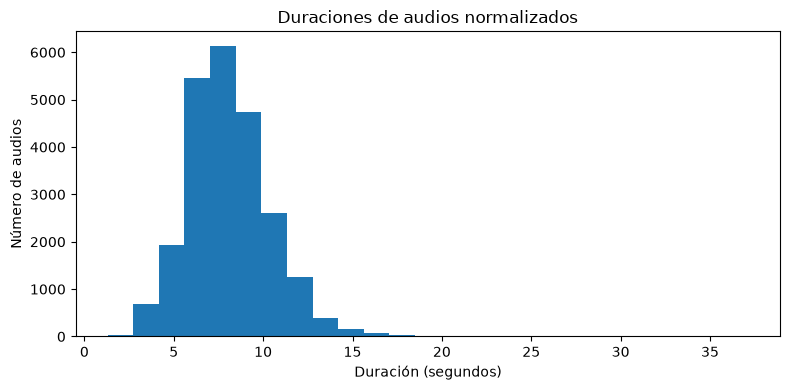

In [21]:
# 8. Resumen técnico y gráficos (por lotes)
if df_dataset.empty:
    print("Aún no hay archivos procesados. Ejecuta la celda 6.")
else:
    resumen = pd.DataFrame({"Indicador": ["Audios originales", "Audios procesados", "Pendientes", "Duración total (horas)", "Duración media (s)", "Frecuencia de muestreo", "Canales", "Subtipo"],
        "Valor": [len(inv), len(df_dataset), len(inv)-len(df_dataset), round(df_dataset["Duracion_s"].sum()/3600, 3),
                  round(df_dataset["Duracion_s"].mean(),3), ", ".join(map(str,sorted(df_dataset["Sample_rate"].unique()))),
                  ", ".join(map(str,sorted(df_dataset["Canales"].unique()))), ", ".join(df_dataset["Subtipo"].unique())]})
    display(resumen)
    resumen.to_csv(METADATA / "reporte_preprocesamiento.csv", index=False, encoding="utf-8-sig")
    plt.figure(figsize=(8,4))
    plt.hist(df_dataset["Duracion_s"], bins=25)
    plt.xlabel("Duración (segundos)")
    plt.ylabel("Número de audios")
    plt.title("Duraciones de audios normalizados")
    plt.tight_layout()
    plt.savefig(REPORTS / "OE1_02_histograma_duracion.png", dpi=180)
    plt.show()

### Controles para la tesis

- El inventario `data/metadata/dataset_procesado.csv` **solo** contiene archivos verificados. El registro `normalizacion_progreso.csv` permite auditar éxitos y errores de cada intento.
- Los WAV de `data/raw/voxforge-es/` se conservan intactos. La normalización puede alterar mínimamente la duración por redondeo de muestras; compruébala en la actividad de evaluación.
- **No mezclar** métricas de la prueba de concepto con VoxForge. El paso siguiente es asociar los `ID_Audio` a los textos `etc/PROMPTS` y validar las referencias.
- Para ejecuciones repetidas, la celda 6 omite archivos ya convertidos y verificados; un archivo fallido se intentará de nuevo.